In [ ]:
!pip install statsmodels
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.graphics.tsaplots import plot_pacf
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df=pd.read_csv("/content/uspopulation.csv")
df.index.freq="MS"
print(df.head())

       DATE  PopEst
0  1/1/2011  311037
1  2/1/2011  311189
2  3/1/2011  311351
3  4/1/2011  311522
4  5/1/2011  311699


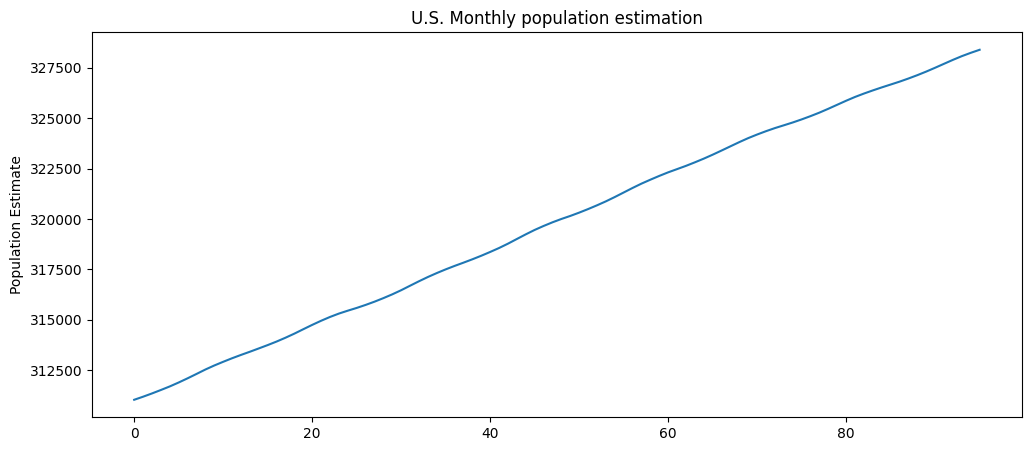

In [ ]:
df["PopEst"].plot(figsize=(12,5),title="U.S. Monthly population estimation")
plt.ylabel("Population Estimate")
plt.show()

In [ ]:
train=df.iloc[:84]
test=df.iloc[84:]
print(len(train),len(test))

84 12


<Figure size 800x400 with 0 Axes>

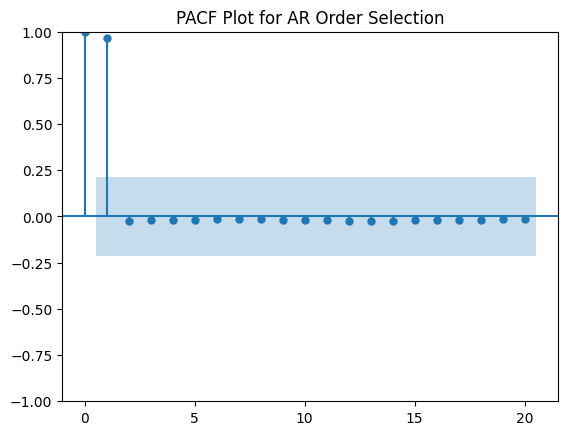

In [ ]:
plt.figure(figsize=(8,4))
plot_pacf(train["PopEst"],lags=20,method='ywm')
plt.title("PACF Plot for AR Order Selection")
plt.show()

In [ ]:
model=AutoReg(train["PopEst"],lags=1).fit()
pred1=model.predict(start=len(train),end=len(train)+len(test)-1,dynamic=False)

model1=AutoReg(train["PopEst"],lags=2).fit()
pred2=model1.predict(start=len(train),end=len(train)+len(test)-1,dynamic=False)

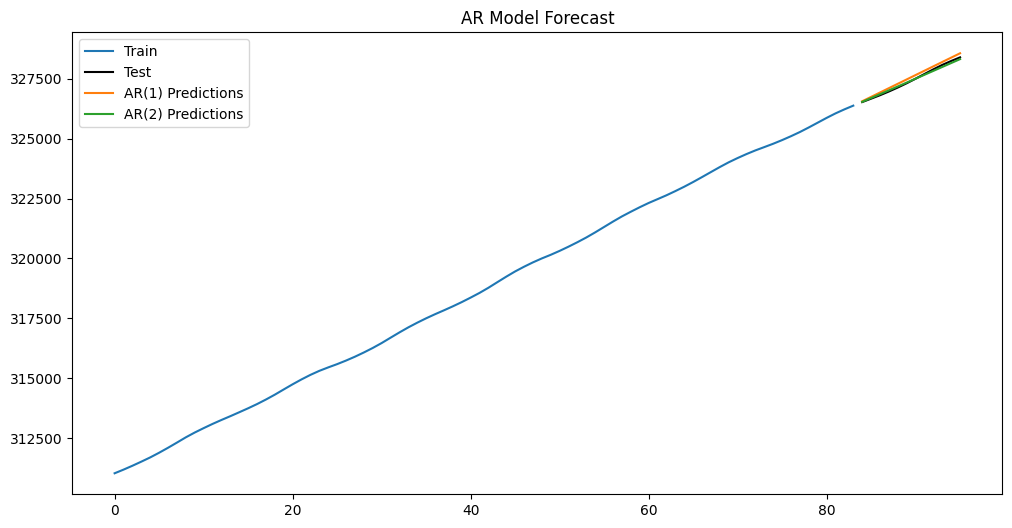

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(train.index,train["PopEst"],label="Train")
plt.plot(test.index,test["PopEst"],label="Test",color='black')
plt.plot(pred1.index,pred1,label="AR(1) Predictions")
plt.plot(pred2.index,pred2,label="AR(2) Predictions")
plt.legend()
plt.title("AR Model Forecast")
plt.show()

In [ ]:
for label,pred in zip(["AR(1)","AR(2)"],[pred1,pred2]):
  error=mean_squared_error(test["PopEst"],pred)
  print(f"{label} MSE:{error:.2f}")

AR(1) MSE:17449.71
AR(2) MSE:2713.26


In [ ]:
final_model=AutoReg(df["PopEst"],lags=2).fit()
forecast=final_model.predict(start=len(df),end=len(df)+11,dynamic=False)
print(forecast.head())

96    NaN
97    NaN
98    NaN
99    NaN
100   NaN
dtype: float64


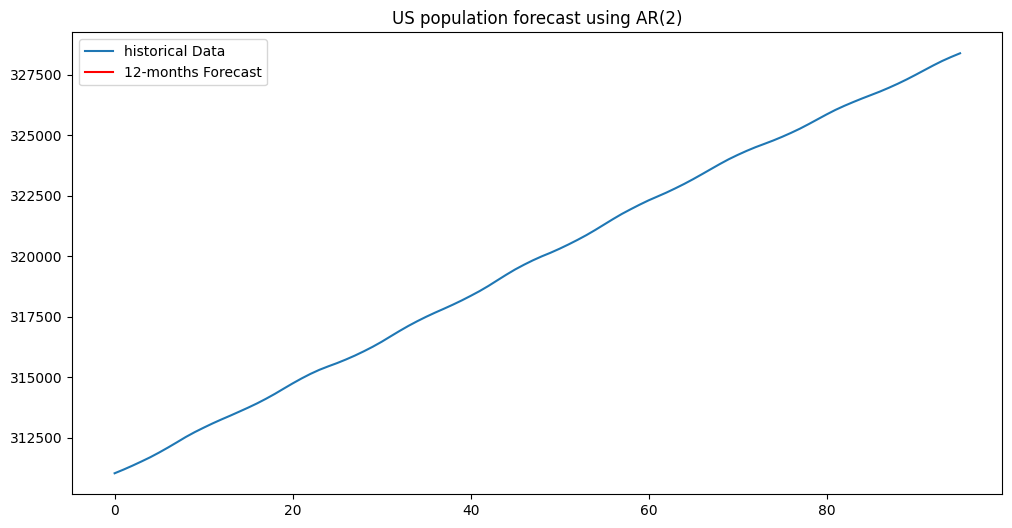

In [ ]:
plt.figure(figsize=(12,6))
plt.plot(df.index,df["PopEst"],label="historical Data")
plt.plot(forecast.index,forecast,label="12-months Forecast",color="red")
plt.legend()
plt.title("US population forecast using AR(2)")
plt.show()
